# Лабораторная работа №2–3. Аппроксимация нелинейных функций

Федотов Георгий Николаевич, ИТ-23Д. **Вариант №37: Y = sin(X) − 2.**

Цель: аппроксимировать заданную функцию полносвязной и ветвящейся нейронными сетями и сравнить ошибки. За основу взяты данные, функции построения моделей, Adam, MSE и порядок обучения из методички по предоставленной ссылке. Скрытые активации оставлены как в её коде: ReLU и Sigmoid; выход линейный и может принимать отрицательные значения.


In [1]:
%pip install -q tensorflow pydot

TensorFlow и pydot установлены в среде проверки.


In [2]:
# Базовые библиотеки
import math
import numpy as np
import matplotlib.pyplot as plt

# Keras / TensorFlow
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Input, concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import utils
import tensorflow as tf
from IPython.display import display

SEED = 37
utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)


TensorFlow: 2.21.0


## 1. Функция и обучающие данные

В методичке t0 — вспомогательный аргумент, а X=2πt0. Для варианта №37 целевая функция вычисляется как sin(X)−2. Сеть получает t0, как в исходном примере. Обучаем её на t0∈[0;1), то есть X∈[0;2π). Истинные значения лежат в пределах от −3 до −1.


Форма данных: (1000, 1) (1000, 1)


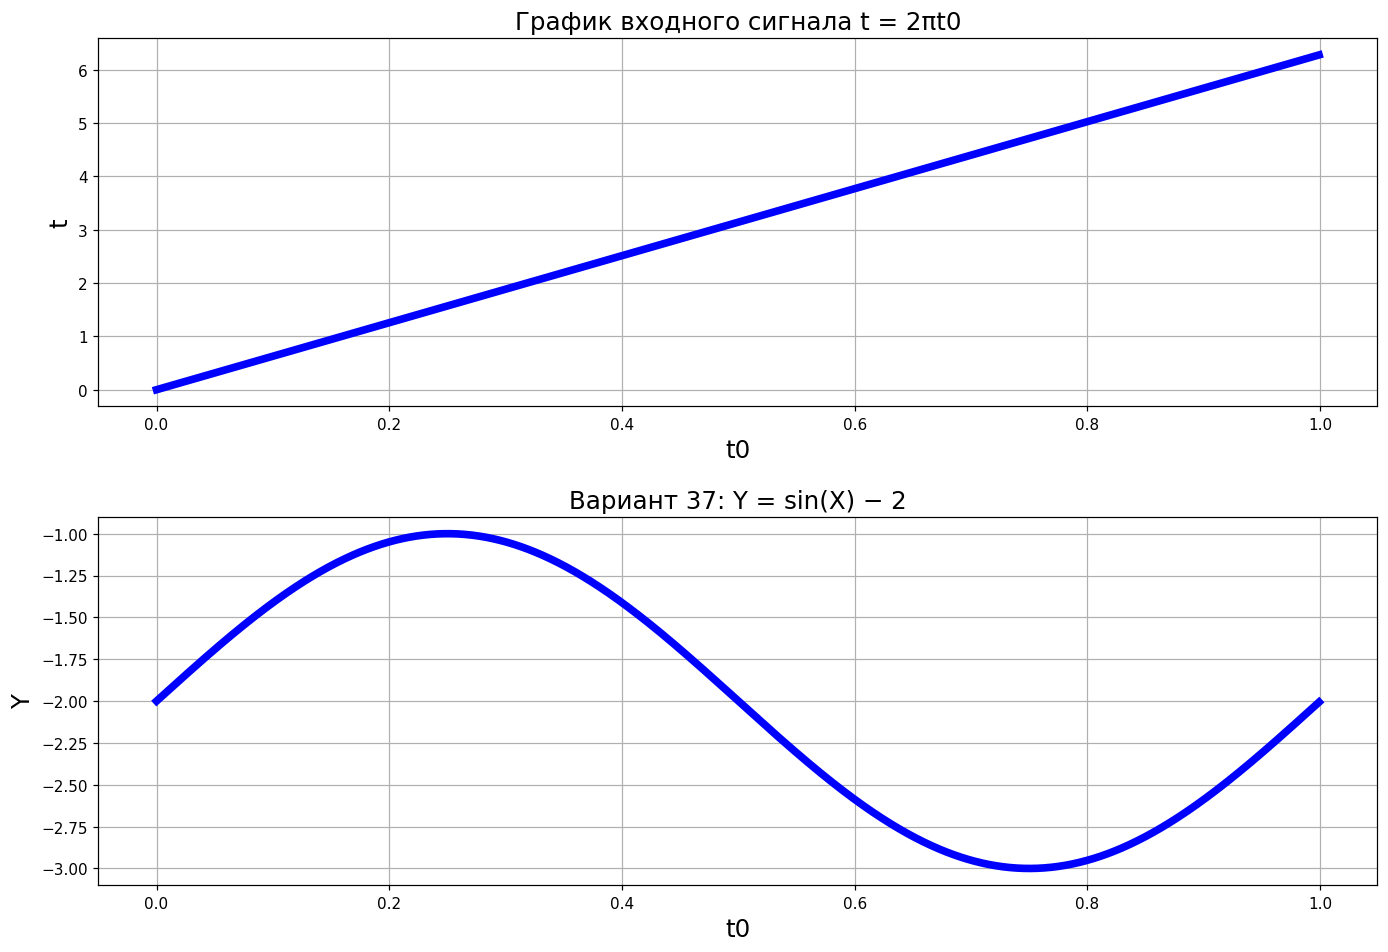

In [3]:
def target_function(X):
    return (np.sin(X) - 2).astype(np.float32)

# Создание обучающей выборки
t0 = np.arange(0, 1, 0.001, dtype=np.float32)
t  = 2 * math.pi * t0
x  = target_function(t)

# Прорисовка графиков обучающей выборки
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
plt.plot(t0, t, "b", linewidth=5)
plt.title("График входного сигнала t = 2πt0", fontsize=16)
plt.ylabel("t", fontsize=16)
plt.xlabel("t0", fontsize=16)
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t0, x, "b", linewidth=5)
plt.title("Вариант 37: Y = sin(X) − 2", fontsize=16)
plt.ylabel("Y", fontsize=16)
plt.xlabel("t0", fontsize=16)
plt.grid()

plt.subplots_adjust(wspace=0, hspace=0.3)  # задаёт зазор между графиками
plt.show()
X_train = t0.reshape(-1, 1)
y_train = x.reshape(-1, 1)
assert X_train.shape == y_train.shape == (1000, 1)
print('Форма данных:', X_train.shape, y_train.shape)


## 2. Модели из методички

Последовательная сеть: вход → Dense(50, ReLU) → Dense(50, ReLU) → Dense(1). Ветвящаяся сеть объединяет основную ветвь из двух ReLU-слоёв и параллельную ветвь Dense(50, Sigmoid). Три функции ниже сохранены из методички; функция Functional показывает альтернативную запись обычной цепочки, а в сравнении используется именно Sequential.


In [4]:
# Модель полносвязной сети для аппроксимации функции
def NN_sin_sequential(in_parameters: int):
    model = Sequential([
        Dense(50, activation="relu", input_shape=(in_parameters,)),
        Dense(50, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.01), loss="mse")
    return model

def NN_sin_functional(in_shape):
    model_input = Input(shape=in_shape)
    x = Dense(50, activation="relu")(model_input)
    x = Dense(50, activation="relu")(x)
    model_out = Dense(1)(x)

    model = Model(model_input, model_out, name="NNSin_Functional")
    model.compile(optimizer=Adam(learning_rate=0.01), loss="mse")
    return model

# Ветвящаяся модель для аппроксимации функции
def NN_sin_branch(in_shape):
    model_input = Input(shape=in_shape)

    # основная ветка
    x_main = Dense(50, activation="relu")(model_input)
    x_main = Dense(50, activation="relu")(x_main)

    # параллельная ветка
    x_branch = Dense(50, activation="sigmoid")(model_input)

    # объединение ветвей
    x_concat = concatenate([x_main, x_branch])

    # выходной слой
    model_out = Dense(1)(x_concat)

    model = Model(model_input, model_out, name="BranchSin_Functional")
    model.compile(optimizer=Adam(learning_rate=0.01), loss="mse")
    return model

Последовательная сеть:
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │           100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,701 (10.55 KB)
 Trainable params: 2,701 (10.55 KB)
 Non-trainable params: 0 (0.00 B)
Та же последовательная архитектура через Functional API:
Model: "NNSin_Functional"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ 

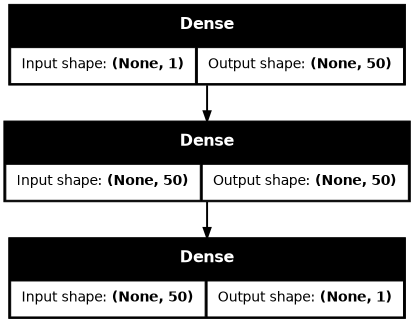

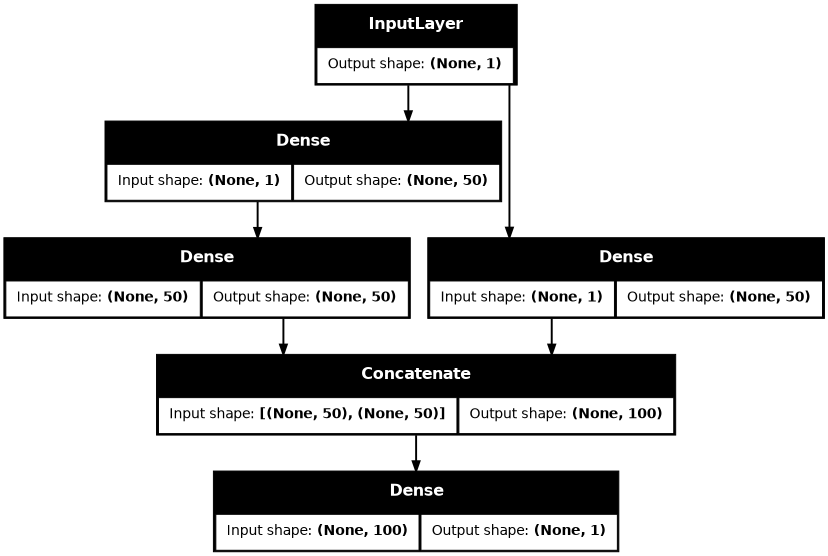

In [5]:
model_sin_seq = NN_sin_sequential(1)
model_sin = NN_sin_functional((1,))
model_branch = NN_sin_branch((1,))
print('Последовательная сеть:')
model_sin_seq.summary()
print('Та же последовательная архитектура через Functional API:')
model_sin.summary()
print('Ветвящаяся сеть:')
model_branch.summary()
display(utils.plot_model(model_sin_seq, dpi=70, show_shapes=True))
display(utils.plot_model(model_branch, dpi=70, show_shapes=True))


## 3. Тестовый интервал

Используем для обеих сетей один и тот же интервал t0∈[1;1,2). Он не пересекается с обучающим и проверяет **экстраполяцию**, а не качество внутри известной области. Формула цели на нём та же: sin(2πt0)−2. Плохая экстраполяция возможна даже при малой обучающей ошибке.


In [6]:
t0_test = np.arange(1, 1.2, 0.001, dtype=np.float32)
t_test = 2 * math.pi * t0_test
x_test = target_function(t_test)
X_test = t0_test.reshape(-1, 1)
y_test = x_test.reshape(-1, 1)
assert t0.max() < t0_test.min()
print('Train:', len(t0), 'точек; test:', len(t0_test), 'точек')


Train: 1000 точек; test: 200 точек


In [7]:
# Функция для расчёта MSE
def compute_mse(y_true, y_pred):
    """
    y_true, y_pred: массивы NumPy одинаковой формы
    """
    y_true = y_true.reshape(-1, 1)
    y_pred = y_pred.reshape(-1, 1)
    return float(np.mean((y_true - y_pred) ** 2))

## 4. Обучение и три настройки для каждой архитектуры

Первый опыт сохраняет параметры методички: learning_rate=0,01, batch_size=30, 100 эпох. Во втором уменьшаем скорость до 0,001, в третьем сохраняем эту скорость и увеличиваем число эпох до 200. Каждый опыт начинается с новой модели. Лишний повторный fit из исходника удалён: количество эпох и история ошибки теперь согласованы. Тестовые данные в обучение не передаются.


In [8]:
settings = [
    {'lr': 0.01,  'batch': 30, 'epochs': 100},
    {'lr': 0.001, 'batch': 30, 'epochs': 100},
    {'lr': 0.001, 'batch': 30, 'epochs': 200},
]
results = []
for architecture, builder in [('NNSin', lambda: NN_sin_sequential(1)),
                               ('BranchSin', lambda: NN_sin_branch((1,)))]:
    for number, setting in enumerate(settings, 1):
        utils.set_random_seed(SEED)
        model = builder()
        model.compile(optimizer=Adam(learning_rate=setting['lr']), loss='mse')
        history_obj = model.fit(X_train, y_train, epochs=setting['epochs'],
                                batch_size=setting['batch'], verbose=0)
        pred_train = model.predict(X_train, verbose=0).ravel()
        pred_test = model.predict(X_test, verbose=0).ravel()
        row = dict(architecture=architecture, number=number, setting=setting,
                   model=model, history=history_obj.history['loss'],
                   pred_train=pred_train, pred_test=pred_test,
                   train_mse=compute_mse(y_train, pred_train),
                   test_mse=compute_mse(y_test, pred_test), params=model.count_params())
        assert np.isfinite(row['train_mse']) and np.isfinite(row['test_mse'])
        results.append(row)
        print(f"{architecture}, опыт {number}, {setting}: "
              f"MSE train={row['train_mse']:.6f}, test={row['test_mse']:.6f}")


NNSin, опыт 1, {'lr': 0.01, 'batch': 30, 'epochs': 100}: MSE train=0.007289, test=0.468274
NNSin, опыт 2, {'lr': 0.001, 'batch': 30, 'epochs': 100}: MSE train=0.005410, test=0.074635
NNSin, опыт 3, {'lr': 0.001, 'batch': 30, 'epochs': 200}: MSE train=0.000875, test=0.011097
BranchSin, опыт 1, {'lr': 0.01, 'batch': 30, 'epochs': 100}: MSE train=0.001007, test=0.082614
BranchSin, опыт 2, {'lr': 0.001, 'batch': 30, 'epochs': 100}: MSE train=0.000468, test=0.039073
BranchSin, опыт 3, {'lr': 0.001, 'batch': 30, 'epochs': 200}: MSE train=0.000100, test=0.004478


## 5. Сравнительные таблицы

Значения заполняются кодом после обучения. Число параметров характеризует размер сети; меньшая MSE означает меньшую среднюю квадратичную ошибку на указанном интервале.


In [9]:
from IPython.display import Markdown
for architecture in ['NNSin', 'BranchSin']:
    table = f'### {architecture}\n\n| Опыт | LR | Batch | Эпохи | Параметры | MSE train | MSE test |\n|---|---|---|---|---|---|---|\n'
    for r in results:
        if r['architecture'] != architecture:
            continue
        s = r['setting']
        table += f"| {r['number']} | {s['lr']} | {s['batch']} | {s['epochs']} | {r['params']} | {r['train_mse']:.6f} | {r['test_mse']:.6f} |\n"
    display(Markdown(table))


### NNSin

| Опыт | LR | Batch | Эпохи | Параметры | MSE train | MSE test |
|---|---|---|---|---|---|---|
| 1 | 0.01 | 30 | 100 | 2701 | 0.007289 | 0.468274 |
| 2 | 0.001 | 30 | 100 | 2701 | 0.005410 | 0.074635 |
| 3 | 0.001 | 30 | 200 | 2701 | 0.000875 | 0.011097 |


### BranchSin

| Опыт | LR | Batch | Эпохи | Параметры | MSE train | MSE test |
|---|---|---|---|---|---|---|
| 1 | 0.01 | 30 | 100 | 2851 | 0.001007 | 0.082614 |
| 2 | 0.001 | 30 | 100 | 2851 | 0.000468 | 0.039073 |
| 3 | 0.001 | 30 | 200 | 2851 | 0.000100 | 0.004478 |


## 6. Графики аппроксимации

Для каждой сети выбираем опыт с наименьшей **обучающей** MSE, не используя тест для подбора. Показываем кривую loss и сравнение с истинной функцией на обоих интервалах.


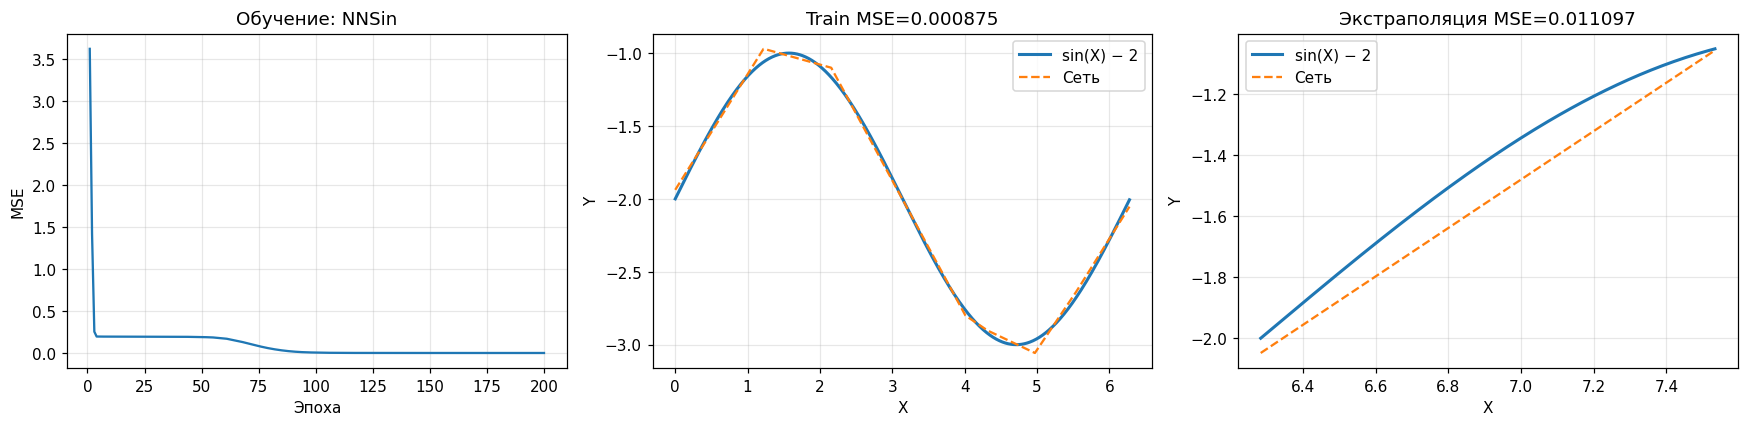

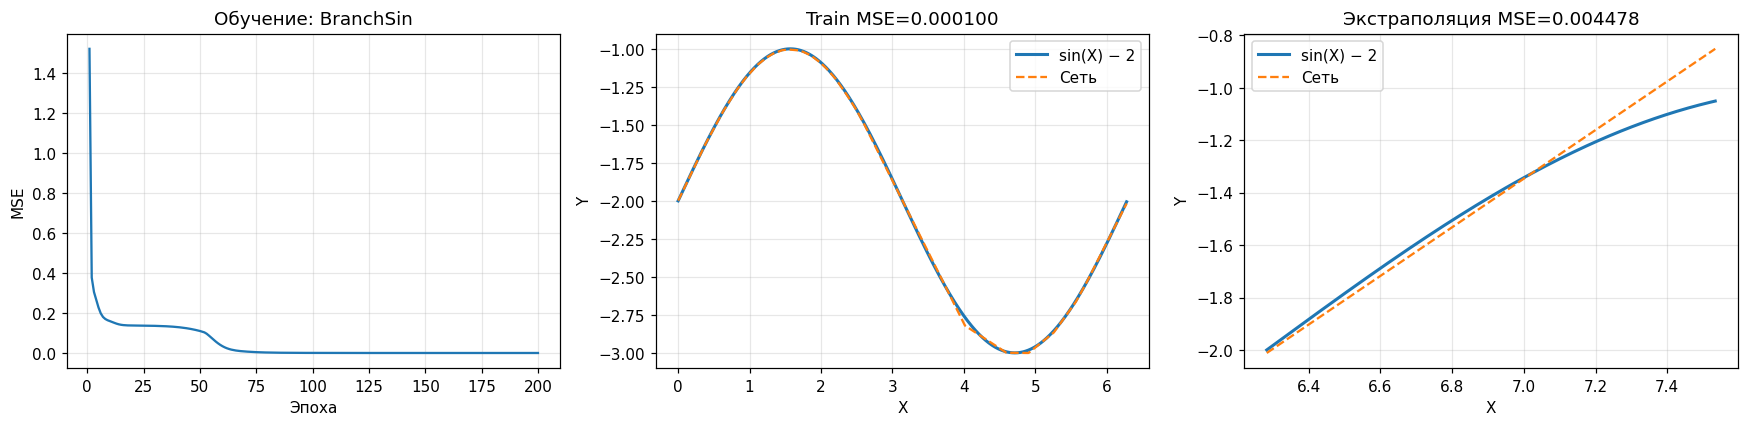

In [10]:
selected = {}
for architecture in ['NNSin', 'BranchSin']:
    r = min((r for r in results if r['architecture'] == architecture), key=lambda r: r['train_mse'])
    selected[architecture] = r
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(np.arange(1, len(r['history']) + 1), r['history'])
    axes[0].set(title='Обучение: ' + architecture, xlabel='Эпоха', ylabel='MSE')
    axes[1].plot(t, x, label='sin(X) − 2', linewidth=2)
    axes[1].plot(t, r['pred_train'], '--', label='Сеть')
    axes[1].set(title=f"Train MSE={r['train_mse']:.6f}", xlabel='X', ylabel='Y')
    axes[2].plot(t_test, x_test, label='sin(X) − 2', linewidth=2)
    axes[2].plot(t_test, r['pred_test'], '--', label='Сеть')
    axes[2].set(title=f"Экстраполяция MSE={r['test_mse']:.6f}", xlabel='X', ylabel='Y')
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[1].legend(); axes[2].legend()
    plt.tight_layout()
    plt.show()


## 7. Проверка ветвящейся сети на тестовом интервале

Это адаптация ячейки, на которую указывала ссылка. Используется та же целевая функция варианта №37.


MSE (test, BranchSin) = 0.004478


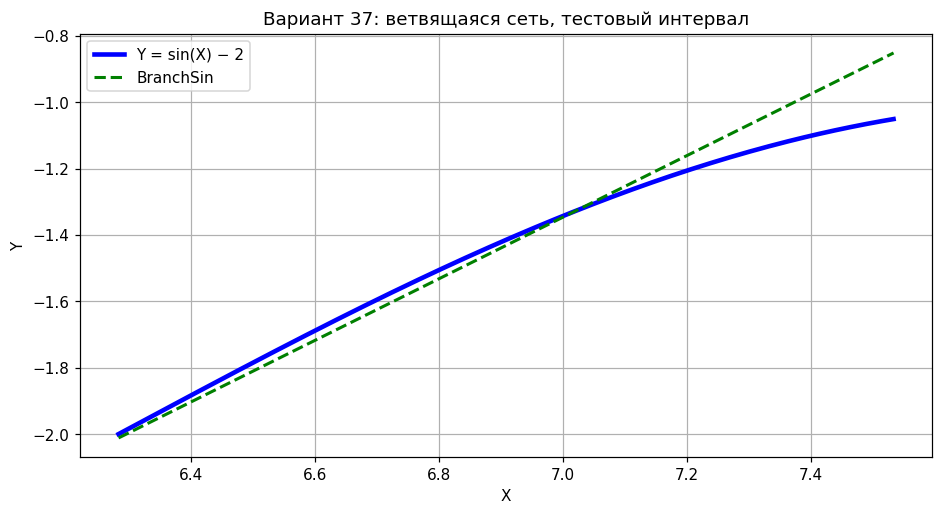

In [11]:
model_branch = selected['BranchSin']['model']
y_branch_test = model_branch.predict(X_test, verbose=0).ravel()
branch_test_mse = compute_mse(y_test, y_branch_test)
print(f'MSE (test, BranchSin) = {branch_test_mse:.6f}')
plt.figure(figsize=(10, 5))
plt.plot(t_test, x_test, 'b', label='Y = sin(X) − 2', linewidth=3)
plt.plot(t_test, y_branch_test, 'g--', label='BranchSin', linewidth=2)
plt.title('Вариант 37: ветвящаяся сеть, тестовый интервал')
plt.ylabel('Y'); plt.xlabel('X'); plt.grid(); plt.legend(); plt.show()


## 8. Выводы

Числовой вывод ниже формируется по реально выполненным опытам. Более сложная архитектура не обязана быть лучше: обучающую и тестовую ошибки необходимо сравнивать отдельно. За границей обучающего интервала сеть не получает гарантии периодического продолжения синуса.


In [12]:
for architecture, r in selected.items():
    print(f"{architecture}: выбран опыт {r['number']} по train MSE; "
          f"параметров {r['params']}; train={r['train_mse']:.6f}, test={r['test_mse']:.6f}")
better = min(selected, key=lambda name: selected[name]['test_mse'])
print('Меньшая тестовая MSE среди выбранных по train моделей:', better)
print('Вывод ограничен указанными интервалами, настройками и одним seed=37.')


NNSin: выбран опыт 3 по train MSE; параметров 2701; train=0.000875, test=0.011097
BranchSin: выбран опыт 3 по train MSE; параметров 2851; train=0.000100, test=0.004478
Меньшая тестовая MSE среди выбранных по train моделей: BranchSin
Вывод ограничен указанными интервалами, настройками и одним seed=37.


## 9. Контрольные вопросы

1. Sequential задаёт цепочку слоёв. Functional API позволяет строить ветви и объединять их; обычную цепочку им тоже можно описать.
2. MSE усредняет квадраты ошибок численного прогноза. Снижение loss показывает уменьшение обучающей ошибки, но не доказывает хорошую экстраполяцию.
3. Слишком большой learning_rate может вызвать колебания и пропуск минимума, слишком маленький — медленное обучение.
4. Batch задаёт число примеров для одного обновления весов. Его изменение влияет на число обновлений за эпоху, скорость и характер колебаний ошибки.
5. Сравнивают MSE и графики обеих сетей на одних данных, а также число параметров. Маленькая train MSE без хорошей test MSE недостаточна для вывода о качестве за пределами обучения.
